# 03 - Spatial EDA by district

**Question:** which of the 25 districts (gu) are most exposed to PM2.5, is that ranking stable from year to year, and how much of the variation is between districts rather than between days?

Each district has one monitoring station, so a district value is the value of its station.

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from seoul_air.data import load_stations
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

In [2]:
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily.parquet")
stations = load_stations()
daily["year"] = daily["date"].dt.year
daily["bad_or_worse"] = daily["pm25_grade"].isin(["Bad", "Very bad"]).where(daily["pm25"].notna())

## 2. District ranking

In [3]:
by_district = daily.groupby("district").agg(
    pm25_median=("pm25", "median"),
    pm25_mean=("pm25", "mean"),
    pm25_bad_or_worse_days_pct=("bad_or_worse", lambda s: s.mean() * 100),
    no2_median=("no2", "median"),
    valid_pm25_days=("pm25", "count"),
).sort_values("pm25_median", ascending=False)
by_district.round(3)

,pm25_median,pm25_mean,pm25_bad_or_worse_days_pct,no2_median,valid_pm25_days
district,,,,,
Gwanak-gu,23.320,26.994,23.161,0.028,1006
Mapo-gu,23.022,26.829,22.200,0.024,1018
Yeongdeungpo-gu,22.271,26.625,21.078,0.028,1058
Yangcheon-gu,21.864,25.770,20.822,0.029,1071
Nowon-gu,21.125,24.301,17.383,0.024,1070
Geumcheon-gu,21.064,24.487,16.948,0.029,1068
Eunpyeong-gu,20.979,24.467,17.308,0.023,1040
Gangdong-gu,20.958,24.419,17.167,0.028,1066
Seongdong-gu,20.956,24.671,18.491,0.027,1060


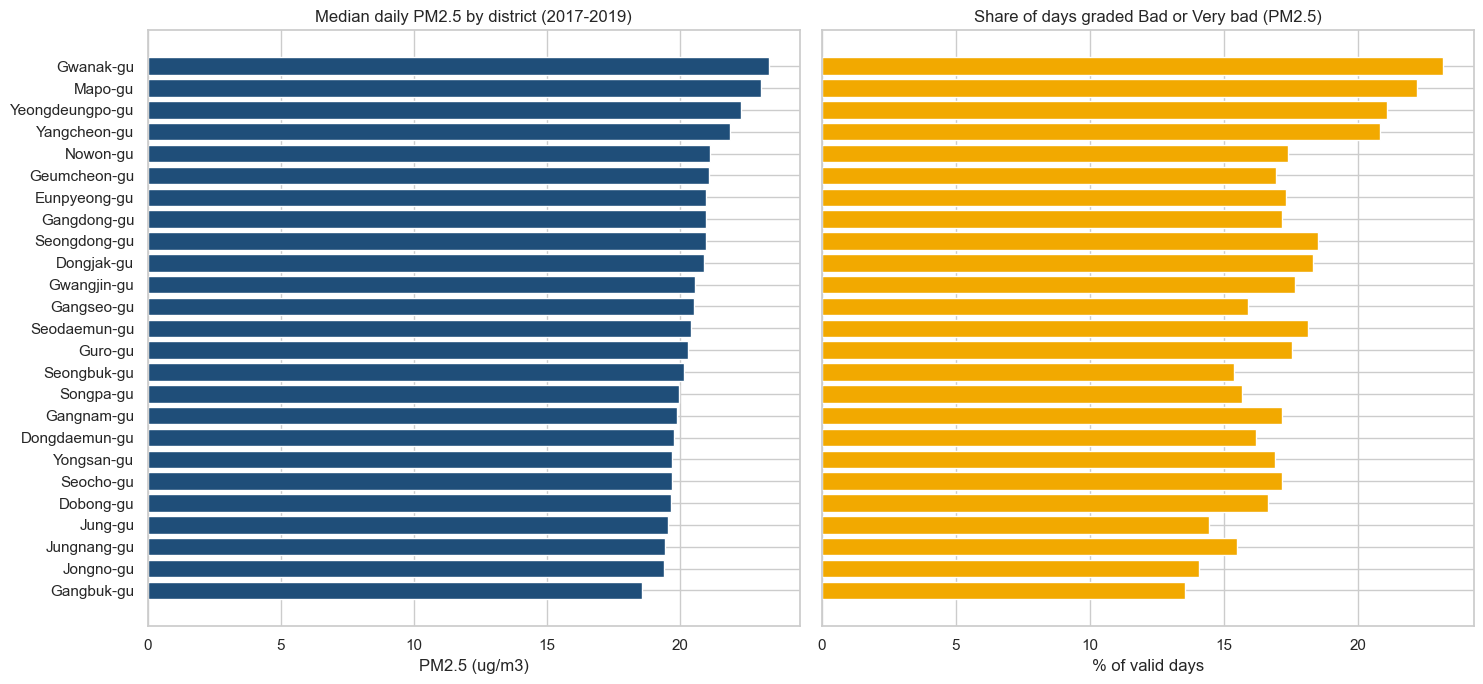

Gap between highest and lowest district median: 4.7 ug/m3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
order = by_district.index
axes[0].barh(order, by_district["pm25_median"], color="#1f4e79")
axes[0].set_title("Median daily PM2.5 by district (2017-2019)")
axes[0].set_xlabel("PM2.5 (ug/m3)")
axes[0].invert_yaxis()
axes[1].barh(order, by_district["pm25_bad_or_worse_days_pct"], color="#f2a900")
axes[1].set_title("Share of days graded Bad or Very bad (PM2.5)")
axes[1].set_xlabel("% of valid days")
fig.tight_layout()
fig.savefig(config.FIGURES / "03_district_ranking.png", dpi=120)
plt.show()
gap = by_district["pm25_median"].max() - by_district["pm25_median"].min()
print(f"Gap between highest and lowest district median: {gap:.1f} ug/m3")

**Interpretation.** Gwanak-gu (23.3 ug/m3), Mapo-gu (23.0) and Yeongdeungpo-gu (22.3) have the highest median daily PM2.5, and Gangbuk-gu the lowest (18.6). The gap between the highest and lowest district is only 4.7 ug/m3, and Gwanak-gu also has the fewest valid days (1,006), with the clean months of September and October 2019 largely missing, which probably pushes its median up. Differences between districts are small compared with differences between seasons.

## 3. Station map

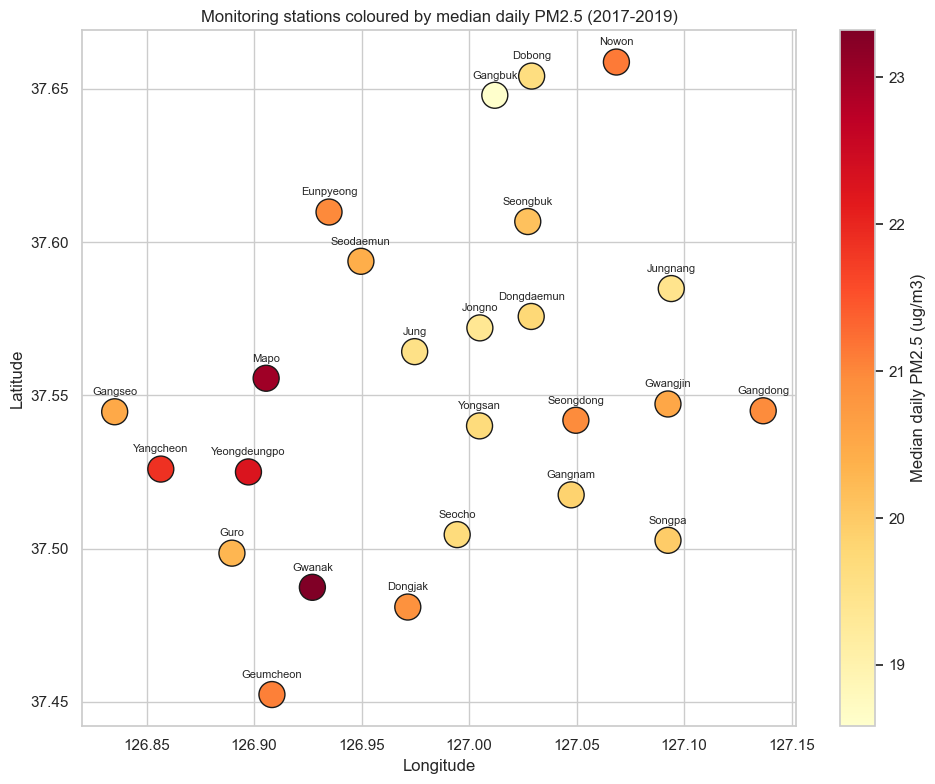

In [5]:
m = stations.merge(by_district, left_on="district", right_index=True)
fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(m["longitude"], m["latitude"], c=m["pm25_median"], s=350, cmap="YlOrRd", edgecolor="k")
for _, r in m.iterrows():
    ax.annotate(r["district"].replace("-gu", ""), (r["longitude"], r["latitude"]),
                textcoords="offset points", xytext=(0, 12), ha="center", fontsize=8)
fig.colorbar(sc, ax=ax, label="Median daily PM2.5 (ug/m3)")
ax.set_title("Monitoring stations coloured by median daily PM2.5 (2017-2019)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.tight_layout()
fig.savefig(config.FIGURES / "03_station_map.png", dpi=120)
plt.show()

## 4. Rank stability across years

In [6]:
yearly = daily.pivot_table(index="district", columns="year", values="pm25", aggfunc="median")
ranks = yearly.rank(ascending=False).astype(int)
print("Spearman correlation of district medians between years:")
print(yearly.corr(method="spearman").round(2).to_string())
ranks.sort_values(ranks.columns[-1]).head(10)

Spearman correlation of district medians between years:
year  2017  2018  2019
year                  
2017  1.00  0.14  0.12
2018  0.14  1.00  0.22
2019  0.12  0.22  1.00


year,2017,2018,2019
district,,,
Yeongdeungpo-gu,23,1,1
Gwanak-gu,3,2,2
Mapo-gu,2,4,3
Gangdong-gu,19,7,4
Nowon-gu,5,17,5
Dongjak-gu,8,23,6
Yangcheon-gu,1,15,7
Gwangjin-gu,18,18,8
Gangseo-gu,16,14,9


**Interpretation.** The district ranking is not stable: the Spearman correlation of district medians between years is only 0.12 to 0.22. Yeongdeungpo-gu, for example, ranks 23rd in 2017 and 1st in 2018 and 2019. A single year of data is not enough to label a district as 'the most polluted'.

## 5. Between-district vs day-to-day variation

In [7]:
wide = daily.pivot_table(index="date", columns="district", values="pm25")
corr = wide.corr()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print(f"Pairwise correlation of daily PM2.5 between districts: min {off_diag.min():.2f}, median {off_diag.median():.2f}")

v = daily.dropna(subset=["pm25"])
total_var = v["pm25"].var()
date_share = 1 - (v["pm25"] - v.groupby("date")["pm25"].transform("mean")).var() / total_var
district_share = 1 - (v["pm25"] - v.groupby("district")["pm25"].transform("mean")).var() / total_var
print(f"Share of station-day variance explained by the date: {date_share:.1%}")
print(f"Share of station-day variance explained by the district: {district_share:.1%}")

Pairwise correlation of daily PM2.5 between districts: min 0.90, median 0.95
Share of station-day variance explained by the date: 94.3%
Share of station-day variance explained by the district: 0.6%


**Interpretation.** Daily PM2.5 moves together across Seoul: the correlation between any two districts is at least 0.90 (median 0.95). The date explains 94.3% of the variance of station-day PM2.5 and the district only 0.6%. PM2.5 in Seoul is a city-wide (and regional) phenomenon, which is why the forecast in notebook 05 uses the city-wide mean as a feature.